DrugBank — база данных лекарственных веществ с химической, фармакологической и фармацевтической информацией, созданной при поддержке
University of Alberta.


 Цели обзора: 

    1.Найти пригодные для статистического исследования величины 
    2.Рассмотреть на практике применимость и информативность различных классических визуализаций данных
    3.Сформулировать гипотезы для проведения исследований
    4.Подготовить данные к полноценному анализу


In [2]:
from pathlib import Path
import sys

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))


Для базового понимания струтуры данных необходимо оценить ряд критериев:
1. Полнота: количество значений и наличие пропусков/NaN/ n/a и пр.
2. Вариативность: количество уникальных значений
3. Численные показатели данных: среднее и медианое значения, стандартное отклонение, среднеквадратичное отклонени

In [ ]:
import pandas as pd

#Посмотрим на сырые данные
df = pd.read_csv(project_root / "drugbank.csv")
df.head(5)

,Unnamed: 0,type,drugbank_id,name,state,cal_logp,cal_logs,cal_water_solubility,cal_molecular_weight,cal_polar_surface_area,...,cal_pka_acidic,cal_pka_basic,cal_physiological_charge,cal_number_of_rings,cal_bioavailability,cal_rule_of_five,exp_molecular_weight,exp_logp,exp_pka,half_life
0,0,biotech,DB00001,Lepirudin,liquid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6963.425,NaN,NaN,Approximately 1.3 hours
1,1,biotech,DB00002,Cetuximab,liquid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,145781.600,NaN,NaN,After administration of a 400 mg/m<sup>2</sup>...
2,2,biotech,DB00003,Dornase alfa,liquid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,29253.900,NaN,NaN,NaN
3,3,biotech,DB00004,Denileukin diftitox,liquid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,57647.300,NaN,NaN,70-80 min
4,4,biotech,DB00005,Etanercept,liquid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,51234.900,NaN,NaN,Etanercept has a mean half-life of elimination...


In [ ]:
from supporting_functions.data_structure import numericReview
numericReview(df)

,dtype,spaces,number of unique values,mean_value,median_value,std,iqr
column_name,,,,,,,
Unnamed: 0,int64,0,14594,7296.5,7296.5,4213.069249,7296.5
type,str,0,2,<NA>,<NA>,<NA>,<NA>
drugbank_id,str,0,14594,<NA>,<NA>,<NA>,<NA>
name,str,0,14594,<NA>,<NA>,<NA>,<NA>
state,str,5476,3,<NA>,<NA>,<NA>,<NA>
cal_logp,float64,3297,994,1.808705,2.06,2.669337,3.43
cal_logs,float64,3774,288,-3.385928,-3.6,1.738364,2.4
cal_water_solubility,str,3774,4234,<NA>,<NA>,<NA>,<NA>
cal_molecular_weight,float64,3294,9726,388.626904,343.4219,331.690302,198.3001


Данные с поменткой 'exp_' - являются экспериментально уточненными и судя по огромным значениям массы это какие-то полимерные структуры, трогать которые, при их столь малом количестве, не имеет смысла.

Колонка 'Unnamed 0:' - просто дублирование индексов

Заметно, что есть 3300 строк для которых отсутствует целый каскад подряд идущих величин, за отсутсвием ценности этих объектов для наших целей, удалим их тоже.

In [4]:
#Применим эти функции к очищенным данным
df_cleaned = pd.read_csv(project_root / "cleaned_data.csv")

numericReview(df_cleaned)

,dtype,spaces,number of unique values,mean_value,median_value,std,iqr
column_name,,,,,,,
type,str,0,1,<NA>,<NA>,<NA>,<NA>
drugbank_id,str,0,10046,<NA>,<NA>,<NA>,<NA>
name,str,0,10046,<NA>,<NA>,<NA>,<NA>
state,str,2346,3,<NA>,<NA>,<NA>,<NA>
cal_logp,float64,0,907,1.857403,2.09,2.352779,3.33
cal_logs,float64,0,285,-3.36356,-3.6,1.710083,2.4
cal_water_solubility,float64,0,4072,24.297727,0.0889,107.09984,1.9787
cal_molecular_weight,float64,0,8625,384.473216,348.793,237.124451,192.337875
cal_polar_surface_area,float64,0,4183,104.251451,86.575,91.663101,61.625


Этих простых действий оказалось достаточно, чтобы обеспечить удовлетварительную полноту выборки. 

После очистки осталось 10 046 объектов. При этом в данных сохраняются пропуски в отдельных столбцах: прежде всего 'state' (23,35%), 'cal_pka_acidic' (10,19%) и 'cal_pka_basic' (3,77%). Последняя нам не сильно интересна - если и будем ее исследовать, то такое незначительное количество пропусков можно будет удалить отдельно.

Фича 'state' - характеризует физическое состояние вещества: твердое или жидкое. Интересно было бы рассмотреть не формируют ли вещества без статуса какую-то отдельную генеральную совокупность. Т.е. связанно ли отсутсвие этой информации с недостатками сбора данных или это признак дополнительной группы.

С 'cal_pka_acidic' всё не так однозначно, но ее в том числе можно будет использовать для проверки генераторов случайных величин для заполнения пропусков в данных. 

Числовые характеристики подтверждают различия в структуре распределений. Для ряда признаков среднее существенно превышает медиану, а стандартное отклонение значительно больше центрального разброса. Поэтому при дальнейшем анализе следует рассматривать не только среднее и стандартное отклонение, но и устойчивые к экстремальным значениям характеристики — медиану и межквартильный размах.

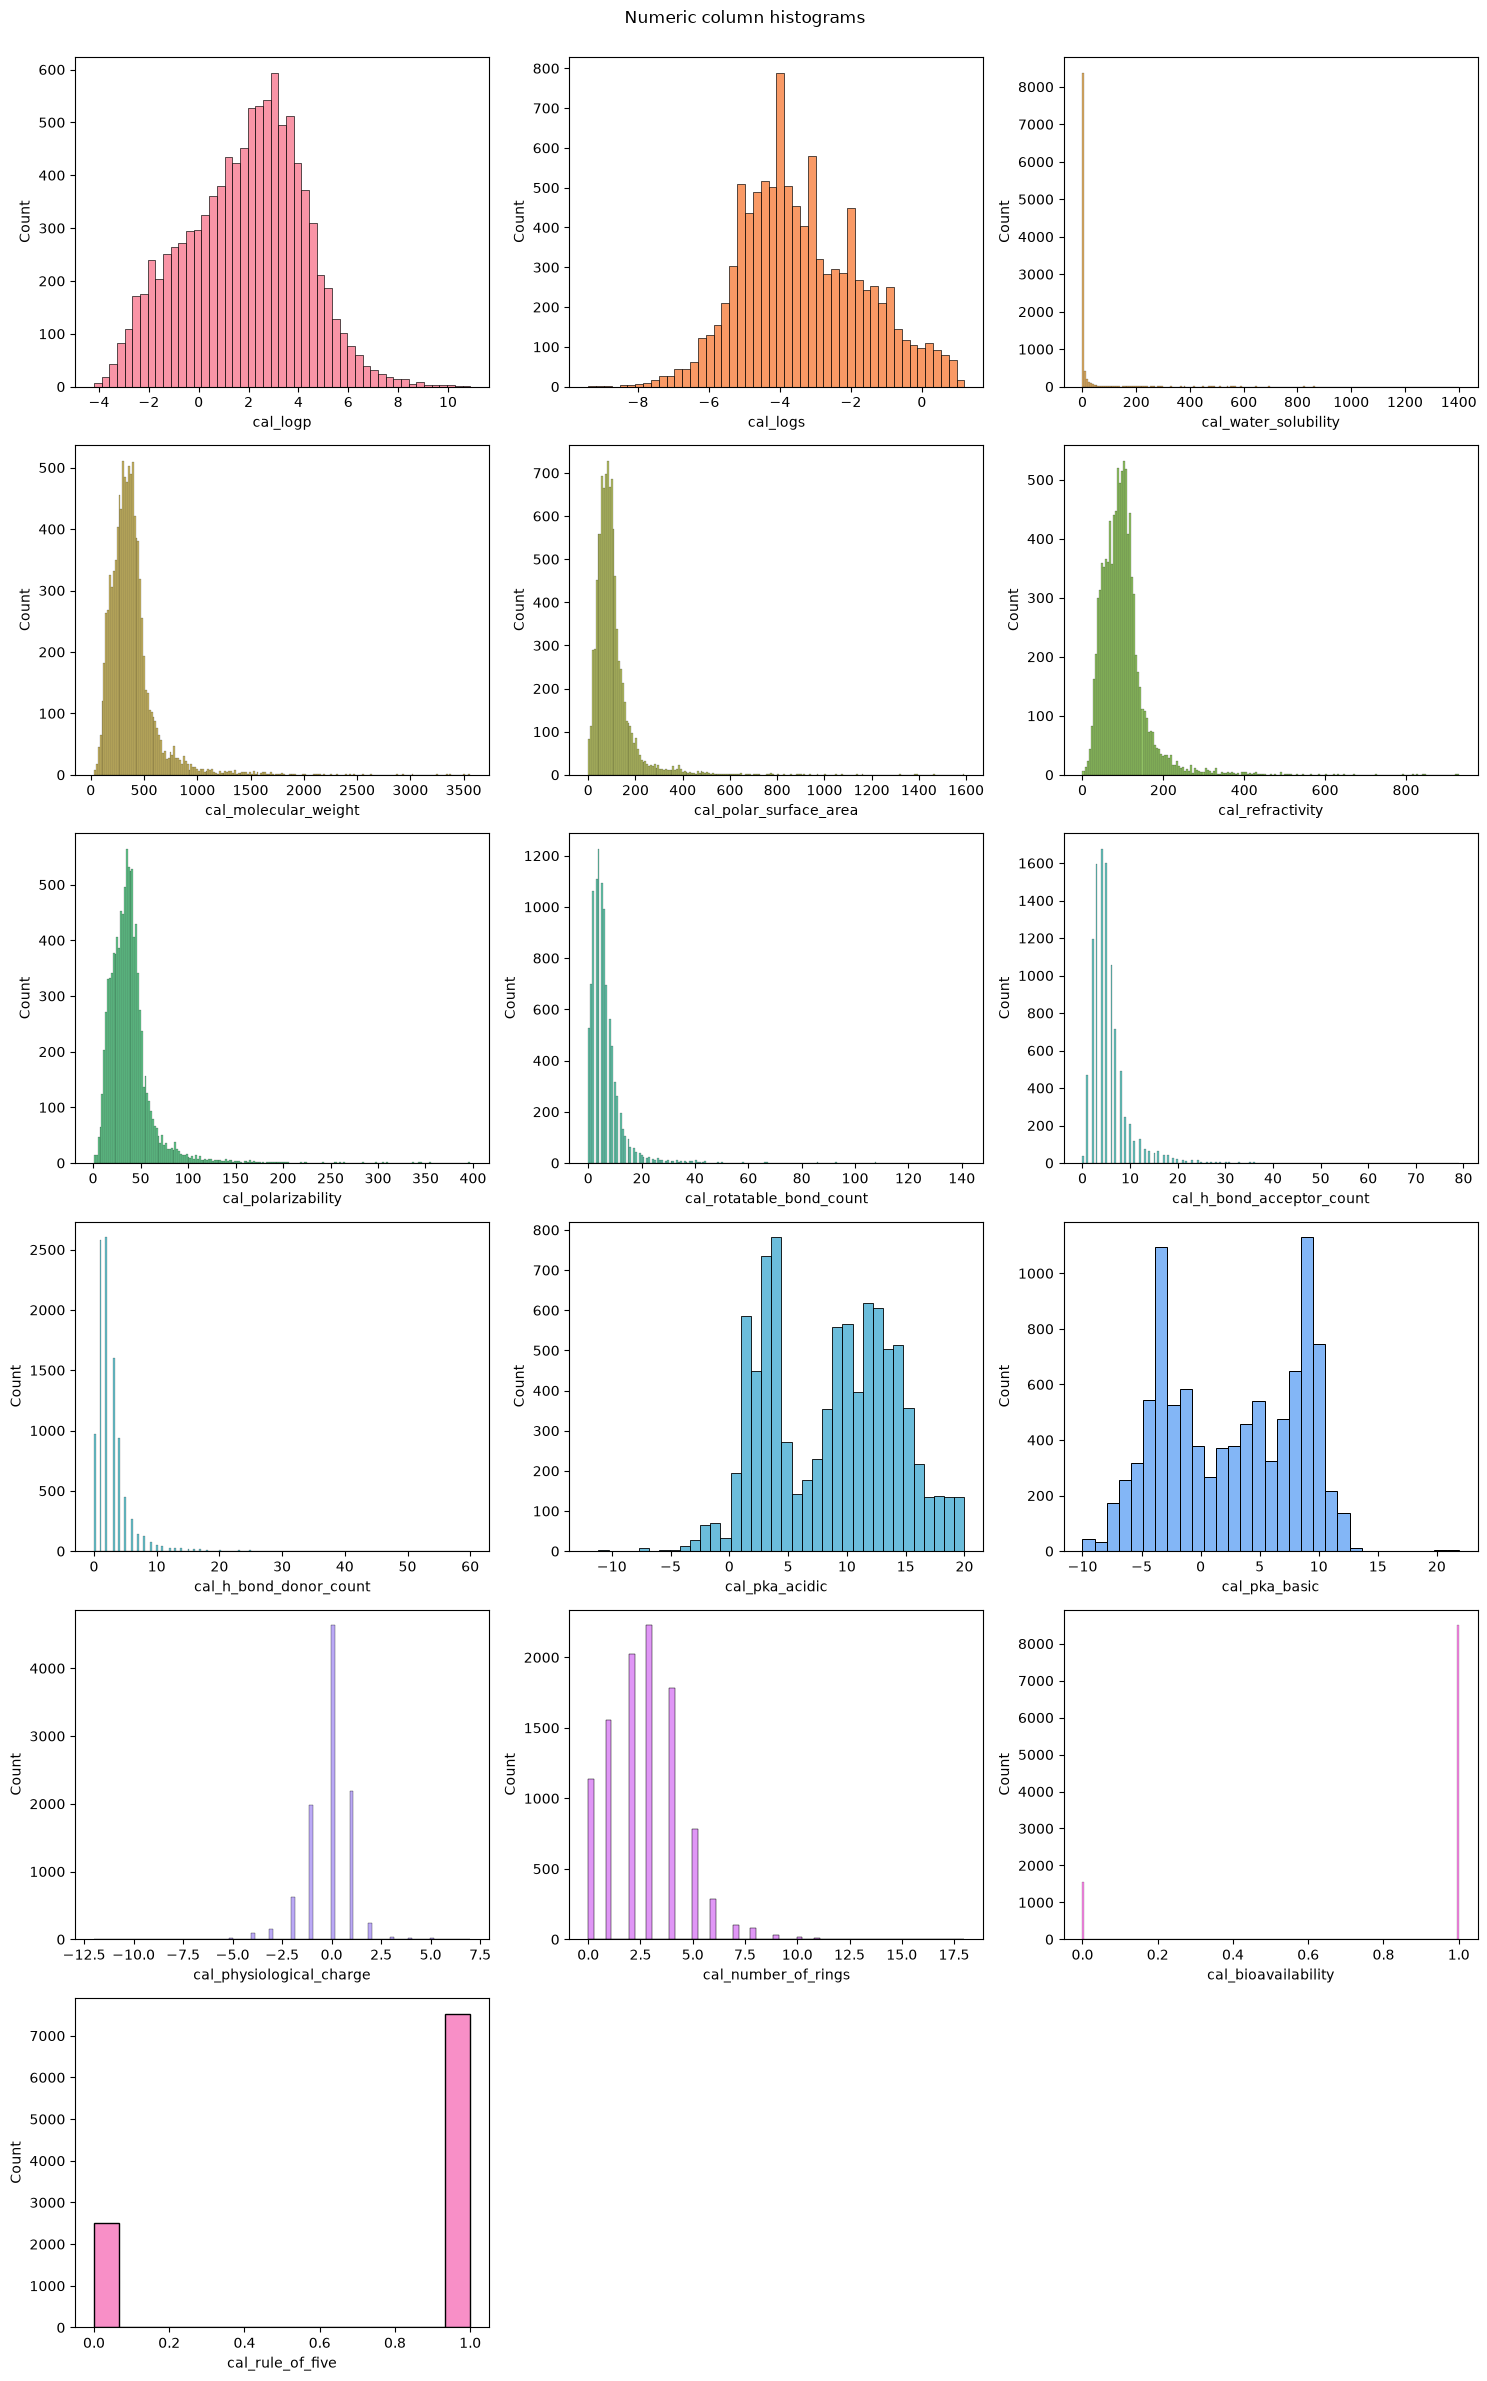

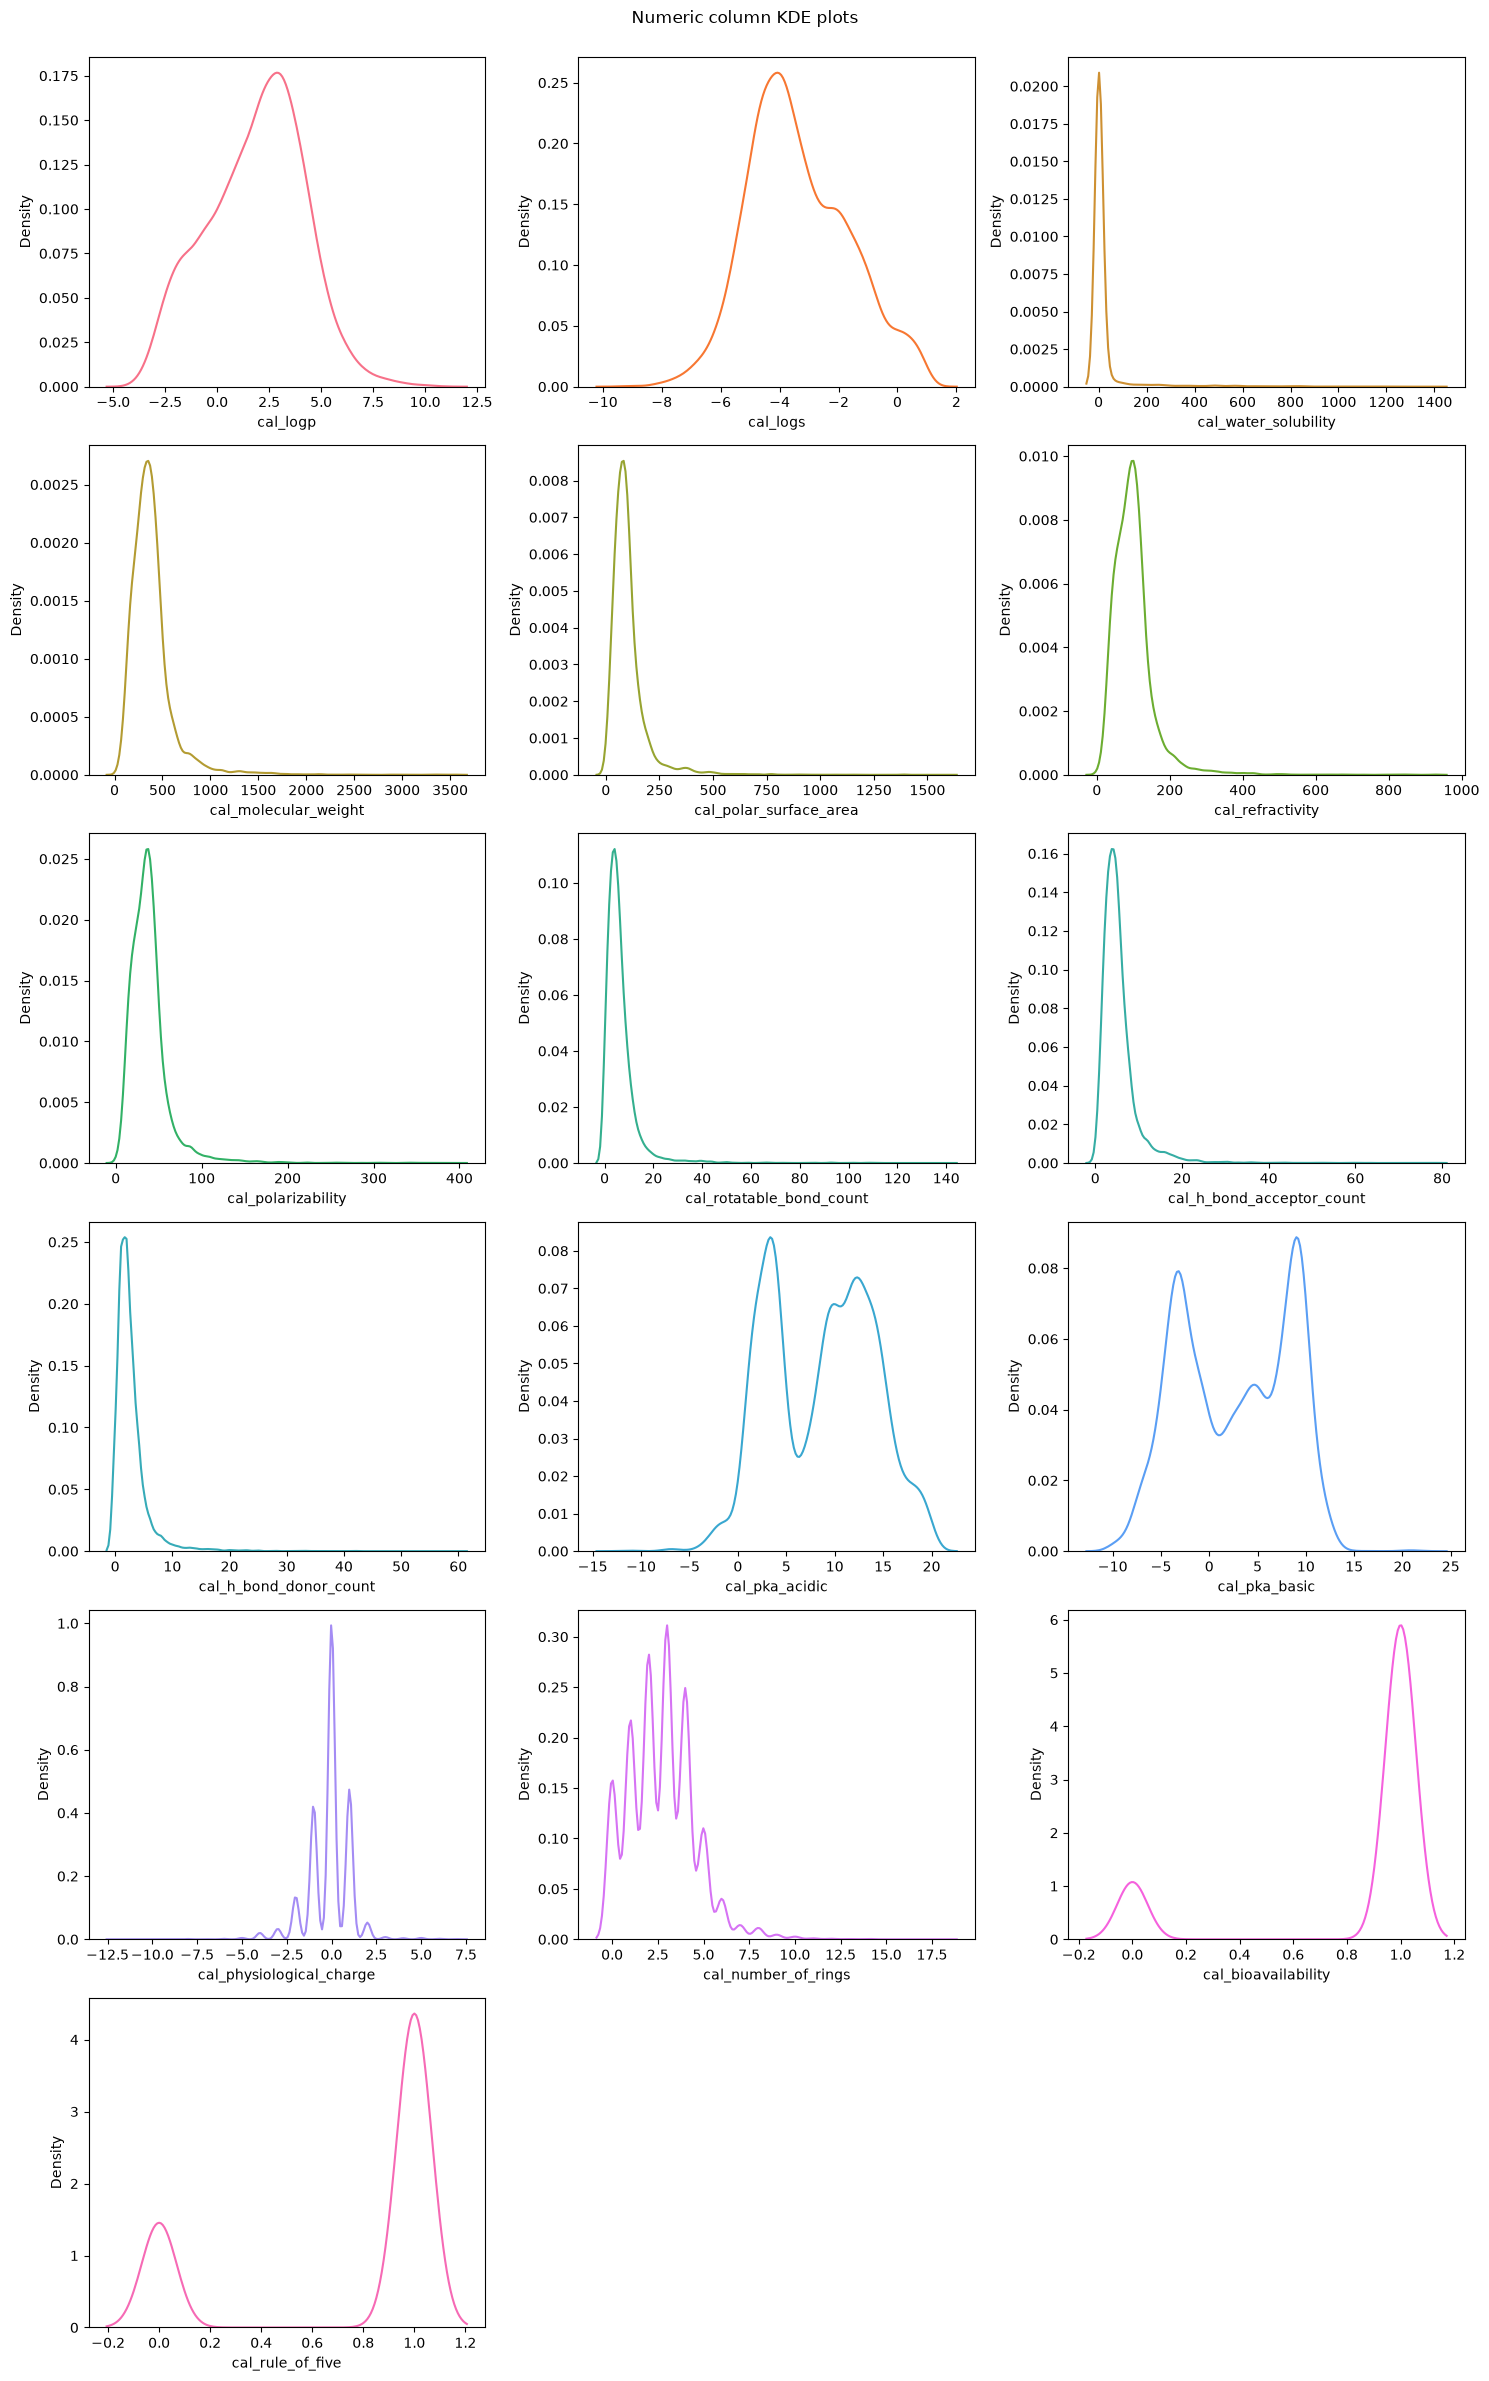

In [13]:
import importlib
import supporting_functions.data_structure as data_structure

importlib.reload(data_structure)

histogram_fig, histogram_axes = data_structure.plot_histograms(df_cleaned)
kde_fig, kde_axes = data_structure.plot_kdes(df_cleaned)

Распределения параметров заметно различаются: 'cal_logp' имеет выраженную область концентрации значений и сравнительно плавную форму.


В свою очередь, 'cal_water_solubility', 'cal_molecular_weight', 'cal_polar_surface_area' и 'cal_polarizability' характеризуются очень сильной положительной асимметрией: большинство наблюдений близкие к нижнему значению диапазона, но хвосты уходят сильно право. Можно поискать логарифмическую зависимость.

'cal_rotatable_bond_count', 'cal_h_bond_acceptor_count', 'cal_h_bond_donor_count' и 'cal_number_of_rings' — счетные характеристики. Для них ожидаются дискретные распределения, что стоит учитывать при разборе.

Распределения 'cal_pka_acidic' и 'cal_pka_basic' имеют несколько выраженных пиков. Это может указывать на неоднородность совокупности соединений, однако причины такой структуры требуют дополнительного исследования.

'cal_bioavailability' и 'cal_rule_of_five' принимают значения 0 и 1, поэтому для них информативнее сравнивать частоты категорий, а не оценивать форму непрерывного распределения. Эти параметры отвечают за самые важные критерии для лекарственных препаратов - биодоступность(т.е. способность к усвоению живим организмом) и правило пяти или же правило Липинского - эмперичесое правило позволяющее понять на сколько вещество "похоже" на лекарство. В качестве параметров для дальнейшей работы их использовать не будем, но можно будет посмотреть корреляции между ними и прочими выделенными категориями на случайных величинах в будущем.

(<Figure size 1500x2400 with 18 Axes>,
 array([[<Axes: xlabel='cal_logp'>, <Axes: xlabel='cal_logs'>,
         <Axes: xlabel='cal_water_solubility'>],
        [<Axes: xlabel='cal_molecular_weight'>,
         <Axes: xlabel='cal_polar_surface_area'>,
         <Axes: xlabel='cal_refractivity'>],
        [<Axes: xlabel='cal_polarizability'>,
         <Axes: xlabel='cal_rotatable_bond_count'>,
         <Axes: xlabel='cal_h_bond_acceptor_count'>],
        [<Axes: xlabel='cal_h_bond_donor_count'>,
         <Axes: xlabel='cal_pka_acidic'>, <Axes: xlabel='cal_pka_basic'>],
        [<Axes: xlabel='cal_physiological_charge'>,
         <Axes: xlabel='cal_number_of_rings'>,
         <Axes: xlabel='cal_bioavailability'>],
        [<Axes: xlabel='cal_rule_of_five'>, <Axes: >, <Axes: >]],
       dtype=object))

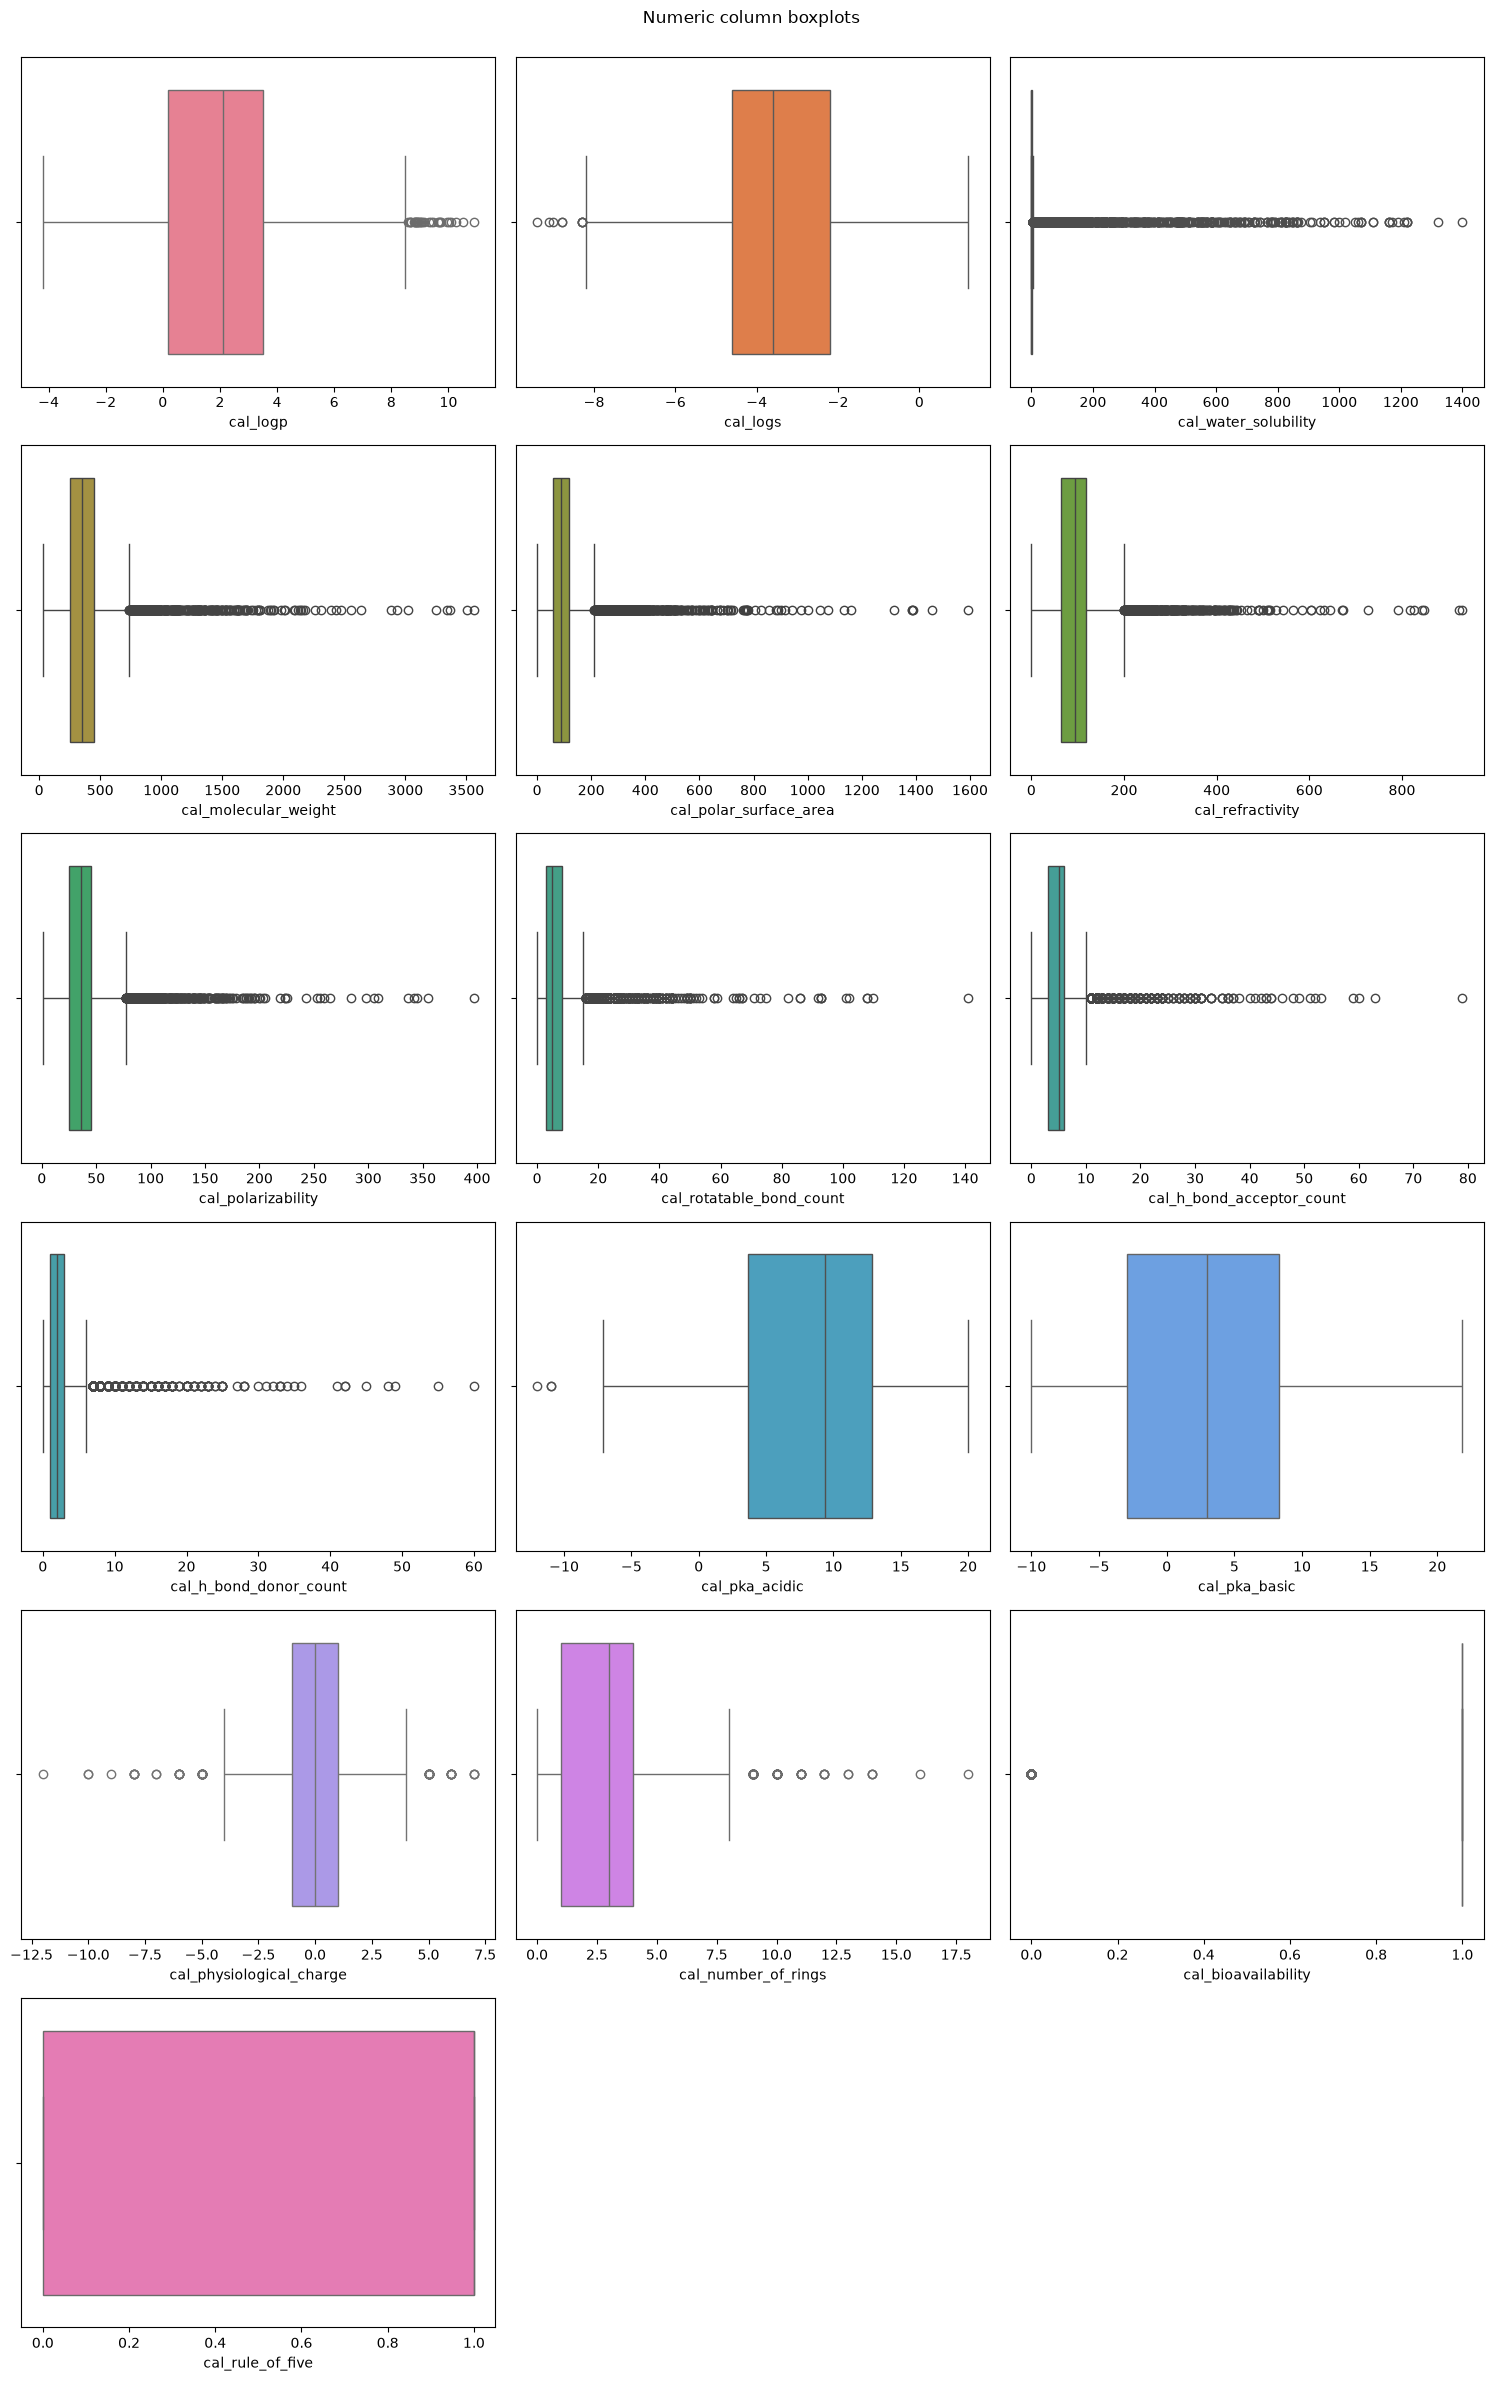

In [14]:
from supporting_functions.data_structure import plot_boxplots
plot_boxplots(df_cleaned)

У большой части характеристик множество точек лежит вне квантильных отступов, что можно принять за выбросы. Но как уже было отмечено выше, распределение может быть логарифмическим или близким к нему, поэтому единственный вывод который можно сделать: для этих категорий требуется нормализация и дополнительное рассмотрение.

Для дискретных величин с малым числом параметров "ящик с усами" применим крайне посредственно, что явно видно на 'cal_bioavailability' и 'cal_rule_of_five'

(column_name                cal_logp  cal_logs  cal_water_solubility  \
 column_name                                                           
 cal_logp                   1.000000 -0.782480             -0.332773   
 cal_logs                  -0.782480  1.000000              0.485106   
 cal_water_solubility      -0.332773  0.485106              1.000000   
 cal_molecular_weight       0.179956 -0.438033             -0.178239   
 cal_polar_surface_area    -0.311901  0.012590             -0.017650   
 cal_refractivity           0.299751 -0.547100             -0.219086   
 cal_polarizability         0.275379 -0.516277             -0.199710   
 cal_rotatable_bond_count   0.114723 -0.331096             -0.121897   
 cal_h_bond_acceptor_count -0.276458  0.012222             -0.010144   
 cal_h_bond_donor_count    -0.376379  0.104707              0.058637   
 cal_pka_acidic             0.318752 -0.173226              0.014743   
 cal_pka_basic             -0.072609 -0.030035             -0.07

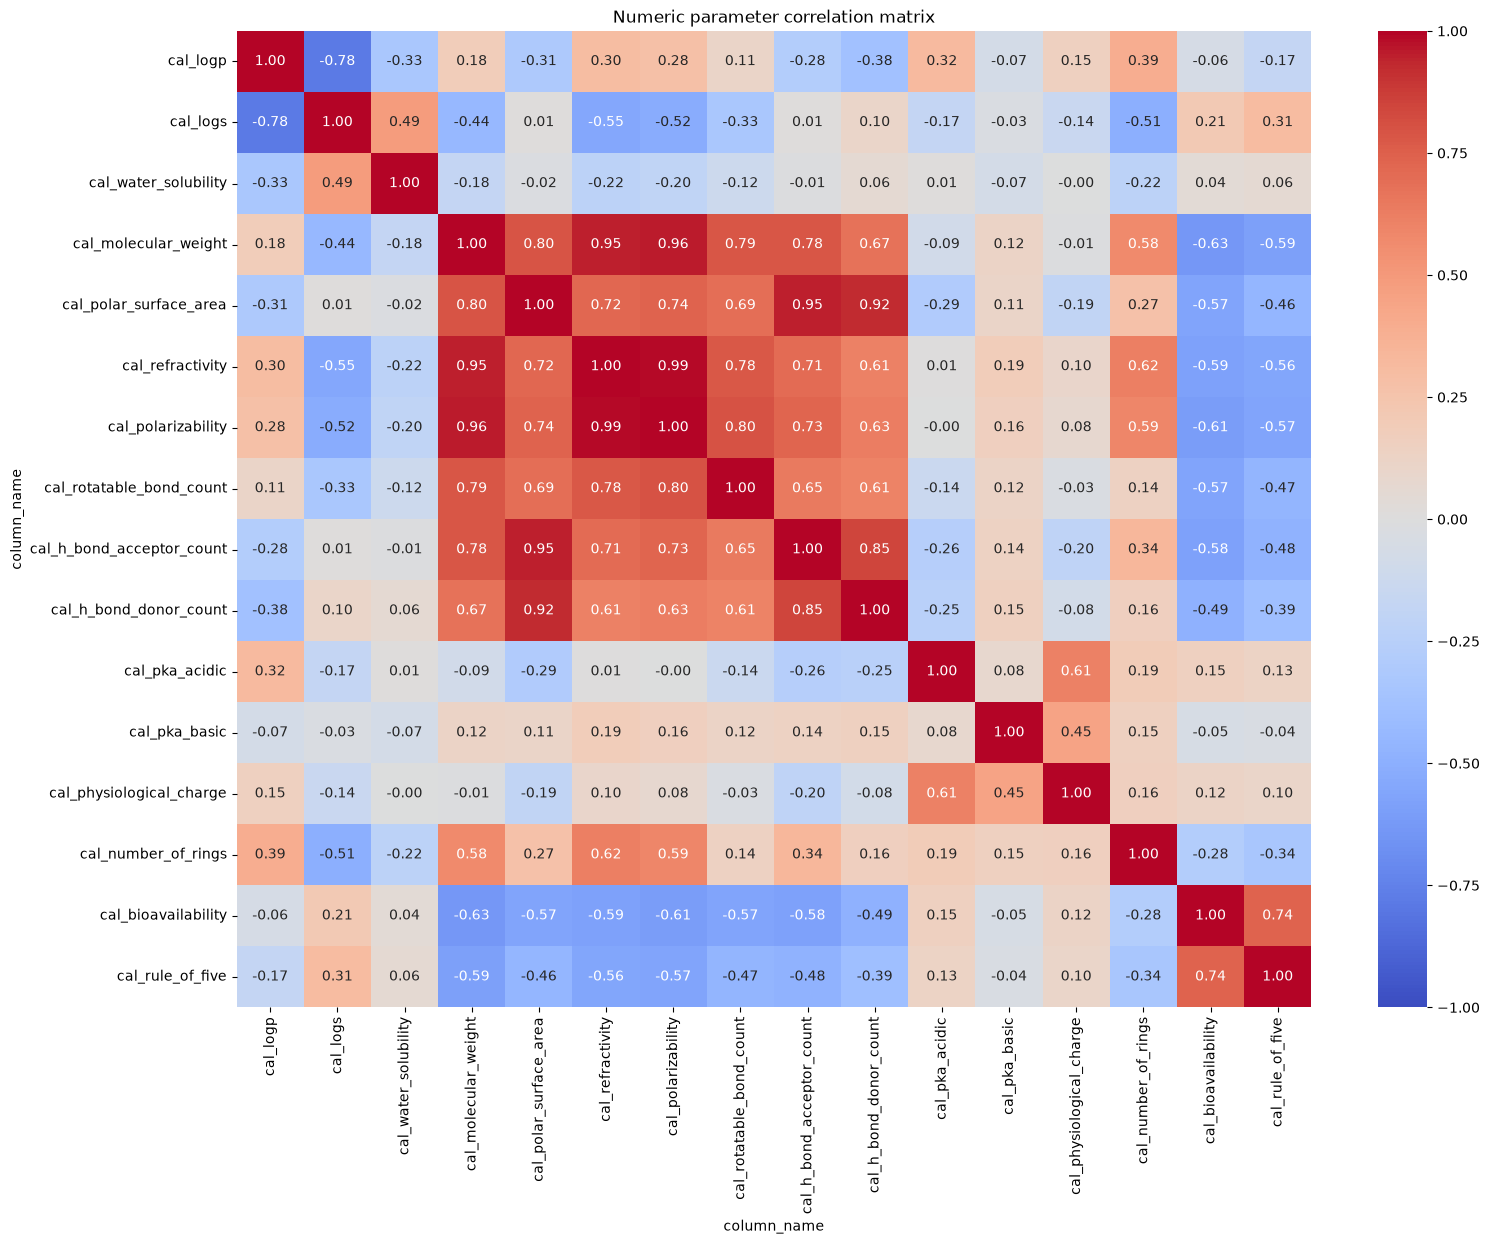

In [16]:
from supporting_functions.data_structure import plot_corr_matrix
plot_corr_matrix(df_cleaned)

### Основные результаты корреляционного анализа

| Пара признаков | Корреляция Пирсона | Интерпретация |
|---|---:|---|
| `cal_refractivity` — `cal_polarizability` | 0,99 | Очень сильная положительная линейная связь |
| `cal_molecular_weight` — `cal_polarizability` | 0,96 | Возможная избыточность признаков |
| `cal_molecular_weight` — `cal_refractivity` | 0,95 | Возможная избыточность признаков |
| `cal_polar_surface_area` — `cal_h_bond_acceptor_count` | 0,95 | Сильная положительная связь |
| `cal_logp` — `cal_logs` | −0,78 | Сильная отрицательная связь |
| `cal_bioavailability` — `cal_rule_of_five` | −0,59 | Умеренно сильная отрицательная связь |

Некоторые физико-химические характеристики сильно связаны и могут частично отражать одни и те же свойства молекул. Это позволяет предположить, что отдельные признаки будут избыточными при совместном использовании в статистических моделях.

Корреляция Пирсона характеризует линейную связь между переменными. Слабая корреляция сама по себе не доказывает независимость, а сильная не означает наличие причинно-следственной связи.

Коэффициент Пирсона можно рассчитывать и для бинарных признаков, например `cal_bioavailability` и `cal_rule_of_five`, однако интерпретировать результат необходимо с учётом их природы.

 Итоги обзора и план дальнейшего исследования

Первичный анализ позволил оценить качество данных, изучить распределения физико-химических характеристик и выявить потенциальные связи между ними. На этой основе сформулированы несколько исследовательских гипотез и подготовлен предварительный план дальнейшей работы.

 1. Предварительные гипотезы

Гипотезы ниже не являются окончательными: по мере анализа выбранных случайных величин могут возникать дополнительные вопросы.

**Гипотеза 1. Отсутствие значения `state` связано с характеристиками вещества.**

В очищенных данных для 23,35% объектов не указано физическое состояние. Интересно узнать, отличаются ли соединения с пропущенным `state` от соединений, для которых оно известно, по распределениям исследуемых физико-химических характеристик.

- \(H_0\): распределения исследуемых характеристик в группах с пропущенным и известным `state` не различаются.
- \(H_1\): распределения хотя бы одной характеристики между группами различаются.

Результат покажет, могут ли пропуски быть связаны со структурой данных, или возникли совершенно случайно, по причине халатности лаборантов *можно мем вставить ахахахах*

**Гипотеза 2. Сильная линейная корреляция позволяет использовать одну характеристику вместо другой без существенной потери информации.**

В матрице корреляций обнаружены пары признаков с сильной положительной связью. Это позволяет исследовать вопрос, насколько разумно рассматривать такие характеристики как потенциально взаимозаменяемые.

- \(H_0\): линейной связи между рассматриваемыми характеристиками нет.
- \(H_1\): между характеристиками существует линейная связь.

Затем следует отдельно оценить, насколько точно одну величину можно предсказывать по другой. Наличие корреляции ещё не означает взаимозаменяемости: для такого вывода необходимо проверить качество предсказания и возможную потерю информации.*надо переформулировать, пока лучше не получилось* 

В первую очередь интерес представляют две пары:

- `cal_refractivity` и `cal_polarizability` — непрерывные характеристики;
- `cal_h_bond_acceptor_count` и `cal_h_bond_donor_count` — дискретные счётные характеристики.

**Гипотеза 3. Распределение физико-химических характеристик различается для групп с разной биодоступностью и соответствием правилу пяти.**

Поля `cal_bioavailability` и `cal_rule_of_five` принимают значения 0 и 1. Интересно разобраться, можно ли найти такие диапазоны значений других физико-химических признаков, в которых вероятность найти те или соответствие этим характеристикам выше или ниже.

Для каждого из двух показателей анализ проводится отдельно.

- \(H_0\): распределение выбранной физико-химической характеристики не различается между группами, заданными значениями 0 и 1.
- \(H_1\): распределения различаются.

Дополнительно можно разделить диапазон физико-химического признака на интервалы и сравнить доли объектов с каждым исходом в этих интервалах. Перед интерпретацией необходимо уточнить, что именно означают значения 0 и 1 в исходных данных.

Таким образом, можно выявить статистическую связь исследуемых величин в ключевые характеристи потенциальных лекарственных препаратов.

**Гипотеза 4. Одновершинная модель недостаточно хорошо описывает распределение `cal_pka_basic`.**

Гистограмма и KDE показывают несколько выраженных пиков. Поэтому необходимо проверить, достаточно ли одной моды для описания распределения или лучше подходит модель, учитывающая несколько групп значений.

- \(H_0\): одновершинная модель является достаточным описанием распределения.
- \(H_1\): одновершинная модель недостаточна.

Наличие нескольких пиков на графике само по себе не доказывает существование нескольких генеральных совокупностей. Вывод должен опираться на дальнейший статистический анализ.

### 2. Предварительные кандидаты для анализа

**`cal_refractivity` и `cal_polarizability` — непрерывные величины с очень сильной корреляцией.**

Молекулярная рефракция связана с поляризуемостью электронного облака и размером молекулы, тогда как поляризуемость характеризует способность электронного облака деформироваться под действием внешнего электрического поля. Корреляция между признаками составляет около 0,99.

Эта пара позволит исследовать распределение непрерывных величин и проверить, насколько оправданно использовать одну характеристику вместо другой.

**`cal_h_bond_acceptor_count` и `cal_h_bond_donor_count` — дискретные счётные величины.**

Первая характеристика описывает число центров молекулы, способных принимать водородную связь, вторая — число центров, способных её отдавать. Корреляция между признаками составляет около 0,85.

Пара представляет интерес для сравнения методов анализа непрерывных и дискретных величин, а также исследования зависимости между двумя характеристиками одной молекулы.


В сути своей, парный анализ величин будет идентичным с точки зрения исполнения, но с дополнительными выводами касательно наличия или отсутствия связей между ними.


**`cal_pka_basic` — непрерывная величина с неоднородным распределением.**

Показатель связан с кислотно-основными свойствами соединения и может использоваться для характеристики его склонности к протонированию и как следствие, вступлению в химические реакции. Наблюдаемая многомодальность делает этот признак интересным кандидатом для исследования теоретического распределения и проверки пригодности одновершинной модели.



### 3. План анализа случайной величины

Для каждой выбранной величины последовательно выполняются следующие этапы.

1. **Обосновать стохастическую природу.** Определить случайную величину как характеристику случайно выбранного объекта из рассматриваемой совокупности. Объяснить, почему её значение варьируется при выборе разных объектов, и обосновать вероятностный подход к анализу.

2. **Исследовать зависимость с другой величиной**, если такая пара выбрана. Сформулировать гипотезу о зависимости или независимости и подобрать подходящий статистический критерий. Одной корреляционной матрицы недостаточно для доказательства независимости.

3. **Эмпирически исследовать состоятельность оценок.** Многократно формировать выборки возрастающего объёма, вычислять оценки выбранных параметров и отслеживать, насколько они приближаются к характеристикам полного набора данных.

4. **Провести EDA и нормализацию.** Описать распределение, оценить центр, разброс, асимметрию и возможные выбросы. При необходимости преобразовать или масштабировать данные, обосновав выбранный метод.

5. **Сформировать выборки с возвращением и без возвращения.** Сравнить выборочные статистики с характеристиками полного набора данных, исследовать влияние объёма выборки и способа отбора на результаты.

6. **Описать математическую модель распределения.** Рассмотреть подходящие теоретические распределения, их параметры и свойства. Обосновать выбор модели исходя из природы величины и наблюдаемой формы распределения.

7. **Проверить исследовательские гипотезы.** Для каждой выбранной проверки указать нулевую и альтернативную гипотезы, уровень значимости, статистический критерий и интерпретацию результата. По условиям задания необходимо проверить как минимум одну гипотезу; остальные проверки выбираются исходя из исследовательских целей.

8. **Сформулировать итог.** Подвести итог по качеству данных, поведению оценок, выбранной модели распределения и результатам проверки гипотез.

### 4. Дальнейшие этапы

Результатом текущего обзора является подготовленный план исследования. В дальнейшем каждая выбранная случайная величина будет изучена по указанной траектории, а результаты анализа позволят перейти к следующему этапу лабораторной работы — разработку и оценку генератора случайной величины.